In [27]:
from basic_packages import *

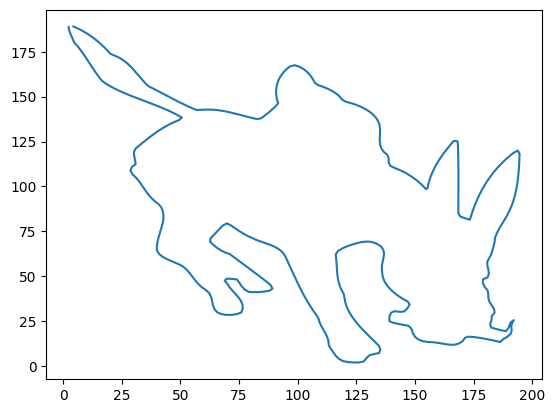

In [28]:
from svgpathtools import svg2paths

paths, attributes = svg2paths("colorado-mines.svg")

path = paths[0]

t = np.linspace(0, 1, 500, endpoint=False)
points = np.array([path.point(ti) for ti in t])

x = points.real
y = points.imag
plt.plot(x, y)
plt.show()

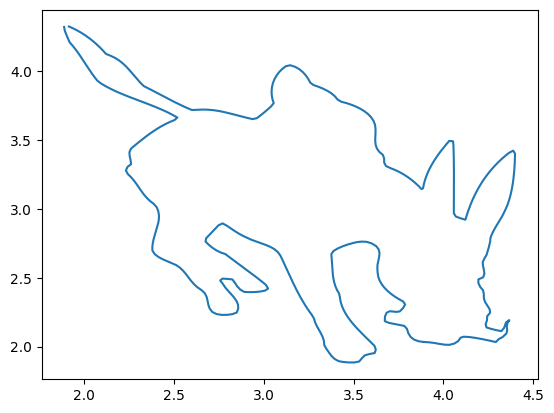

In [29]:
current_min = min(np.min(x), np.min(y))
current_max = max(np.max(x), np.max(y))

desired_min = .3* 2* np.pi
desired_max = .7* 2* np.pi

scale = (desired_max - desired_min) / (current_max - current_min)
x_scaled = desired_min + (x - current_min) * scale
y_scaled = desired_min + (y - current_min) * scale

plt.plot(x_scaled, y_scaled)
plt.show()

In [30]:
def sample_and_compact(x, y, N):
    assert x.shape == y.shape, "x and y must have the same shape"
    assert N > 0, "N must be positive"
    assert N <= len(x), "N must be less than or equal to the length of x and y"
    indices = np.linspace(0, len(x)-1, N, dtype=int)
    x_sampled = x[indices]
    y_sampled = y[indices]
    return [x_sampled, y_sampled]

float64


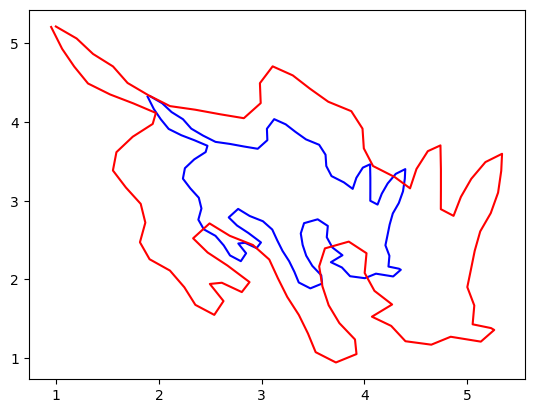

In [31]:
x_ib = sample_and_compact(x_scaled, y_scaled, 100)

print(x_scaled.dtype)

desired_min_inside = .15* 2* np.pi
desired_max_inside = .85* 2* np.pi

scale = (desired_max_inside - desired_min_inside) / (current_max - current_min)
x_scaled_inside = desired_min_inside + (x - current_min) * scale
y_scaled_inside = desired_min_inside + (y - current_min) * scale
x_ib_inside = sample_and_compact(x_scaled_inside, y_scaled_inside, 100)

plt.plot(x_ib[0], x_ib[1], color='blue')
plt.plot(x_ib_inside[0], x_ib_inside[1], color='red')
plt.show()

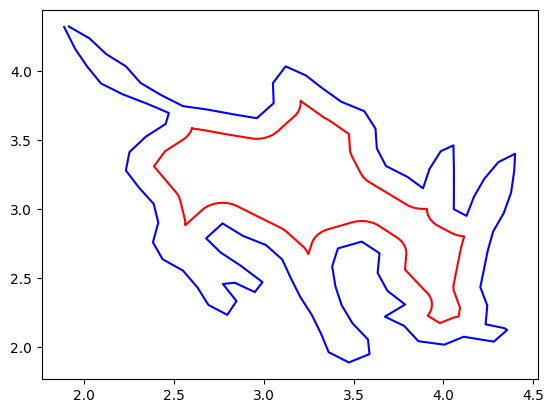

Interior boundary points shape: (100,)


In [32]:
from shapely.geometry import Polygon

# x, y are your original boundary coordinates
points = np.column_stack((x_ib[0], x_ib[1]))

polygon = Polygon(points)

# Shrink inward by distance d
d = 0.15
inner_polygon = polygon.buffer(-d)

if inner_polygon.geom_type == "Polygon":
    polygons = [inner_polygon]
elif inner_polygon.geom_type == "MultiPolygon":
    polygons = list(inner_polygon.geoms)
else:
    polygons = []

boundaries = []

for p in polygons:
    x_inner, y_inner = p.exterior.xy
    boundaries.append(np.column_stack((x_inner, y_inner)))

x_ib_inner = [np.asarray(boundaries[0][:,0]), np.asarray(boundaries[0][:,1])]

if len(boundaries) > 1:
    for i in range(1, len(boundaries)):
        x_ib_inner[0] = np.concatenate((x_ib_inner[0], np.asarray(boundaries[i][:,0])))
        x_ib_inner[1] = np.concatenate((x_ib_inner[1], np.asarray(boundaries[i][:,1])))

x_ib_inner = sample_and_compact(x_ib_inner[0], x_ib_inner[1], 100)

plt.plot(x_ib[0], x_ib[1], color='blue')
plt.plot(x_ib_inner[0], x_ib_inner[1], color='red')
plt.show()

print("Interior boundary points shape:", x_ib_inner[0].shape)

In [33]:
def u_bdy(x, t):
    # return 1 + .05*((x[0]-np.pi)*np.cos(t/5)
    #             + (x[1]-np.pi)*np.sin(t/5)) + 0.02*np.cos(t/2)
    return 1.0

def u(x, t, amplitudes, kx, ky, kt, phases, wave_types):
    # result = np.zeros_like(np.asarray(x[0]) + np.asarray(x[1]), dtype=float)

    # for j in range(5):
    #     theta = kx[j]*x[0] + ky[j]*x[1] + kt[j]*t + phases[j]
    #     trig = np.sin if wave_types[j] == "sin" else np.cos

    #     result += amplitudes[j] * trig(theta)

    # return result

    return 0.0

def f(x, t, amplitudes, kx, ky, kt, phases, wave_types):
    # """Spatial Laplacian of u: f = u_xx + u_yy."""
    # result = np.zeros_like(np.asarray(x[0]) + np.asarray(x[1]), dtype=float)

    # for j in range(5):
    #     theta = kx[j]*x[0] + ky[j]*x[1] + kt[j]*t + phases[j]
    #     trig = np.sin if wave_types[j] == "sin" else np.cos

    #     result -= (
    #         amplitudes[j]
    #         * (kx[j]**2 + ky[j]**2)
    #         * trig(theta)
    #     )

    # return result
    return 0.0



In [34]:
#Reskin of HW0 Finite difference code. 
#Except this time we will put everything inside defined functions for ease of use.

def make_grid(a, b, N):
    lnspc = np.linspace(a, b, N+1)
    return np.row_stack((lnspc, lnspc))

def get_interior_index(i, j, N):    
    assert 1 <= i < N
    assert 1 <= j < N
    return (i-1)*(N-1) + (j-1)

def get_boundary_index(i, j, N):
    assert i == 0 or i == N or j == 0 or j == N, "Point is not on the boundary"
    if i == 0:
        return j  # Top boundary
    if i == N:
        return N + j + 1  # Bottom boundary
    if j == 0:
        return 2*N + i + 1 # Left boundary
    if j == N:
        return 3*N + i # Right boundary

def populate_A(A, N):
    for i in range(1, N):
        for j in range(1, N):
            A[get_interior_index(i, j, N), get_interior_index(i, j, N)] = -4    #Self-reference term
            if i > 1:
                A[get_interior_index(i, j, N), get_interior_index(i-1, j, N)] = 1 #Above neighbor compressed to row-major order
            if i < N-1:
                A[get_interior_index(i, j, N), get_interior_index(i+1, j, N)] = 1 #Below neighbor compressed to row-major order
            if j > 1:
                A[get_interior_index(i, j, N), get_interior_index(i, j-1, N)] = 1 #Left neighbor compressed to row-major order
            if j < N-1:
                A[get_interior_index(i, j, N), get_interior_index(i, j+1, N)] = 1 #Right neighbor compressed to row-major order
    return A

def populate_B_bd(B_bd, N):
    for i in range(1, N):
        for j in range(1, N):
            if i == 1:
                B_bd[(i-1)*(N-1) + (j-1), get_boundary_index(i-1, j, N)] = 1 #Top boundary compressed to row-major order. Note that the index of the boundary matrix is offset from the interior point matrix. 
            if i == N-1:
                B_bd[(i-1)*(N-1) + (j-1), get_boundary_index(i+1, j, N)] = 1 #Bottom boundary compressed to row-major order.
            if j == 1:
                B_bd[(i-1)*(N-1) + (j-1), get_boundary_index(i, j-1, N)] = 1 #Left boundary compressed to row-major order.
            if j == N-1:
                B_bd[(i-1)*(N-1) + (j-1), get_boundary_index(i, j+1, N)] = 1 #Right boundary compressed to row-major order.
    return B_bd

def make_A(N, h):
    A = sp.sparse.lil_matrix(((N-1)**2, (N-1)**2))
    A = populate_A(A, N)
    return A.tocsr() * (1/h**2)

def make_B_bd(N, h):
    B_bd = sp.sparse.lil_matrix(((N-1)**2, 4*N))
    B_bd = populate_B_bd(B_bd, N)
    return B_bd.tocsr() * (1/h**2)

def make_u_bd(N, u, x):
    u_bd = np.zeros(4*N)
    for i in range(N+1):
        for j in range(N+1):
            if i == 0 or i == N or j == 0 or j == N:
                u_bd[get_boundary_index(i, j, N)] = u([x[0][i], x[1][j]])
    return u_bd

def make_f_vec(N, f, x):
    f_vec = np.zeros((N-1)**2)
    for i in range(1, N):
        for j in range(1, N):
            f_vec[get_interior_index(i, j, N)] = f([x[0][i], x[1][j]])
    return f_vec

def make_rhs(f_vec, B_bd, u_bd):
    return f_vec - B_bd @ u_bd

def full_system(N, a, b, u, f):
    h = (b-a) / N
    x = make_grid(a, b, N)
    A = make_A(N, h)
    B_bd = make_B_bd(N, h)
    u_bd = make_u_bd(N, u, x)
    f_vec = make_f_vec(N, f, x)
    b = make_rhs(f_vec, B_bd, u_bd)
    u_approx = sp.sparse.linalg.spsolve(A, b)
    return u_approx

def get_exact(N, a, b, u):
    x = make_grid(a, b, N)
    u_exact = np.zeros((N-1)**2)
    for i in range(1, N):
        for j in range(1, N):
            u_exact[get_interior_index(i, j, N)] = u([x[0][i], x[1][j]])
    return u_exact

C:\Users\cjgir\AppData\Local\Temp\ipykernel_23936\2432620283.py:6: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  return np.row_stack((lnspc, lnspc))


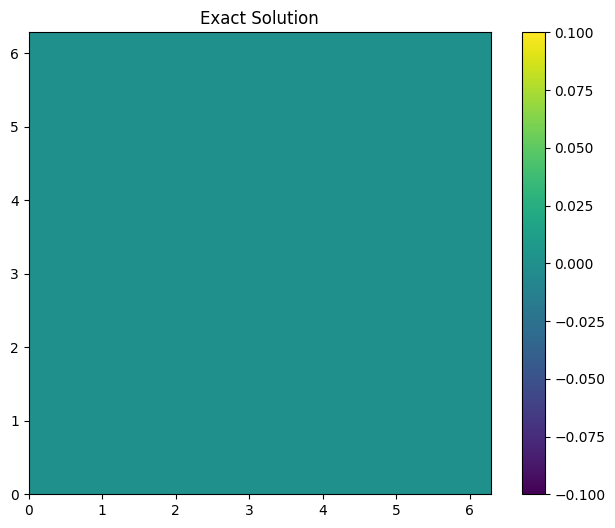

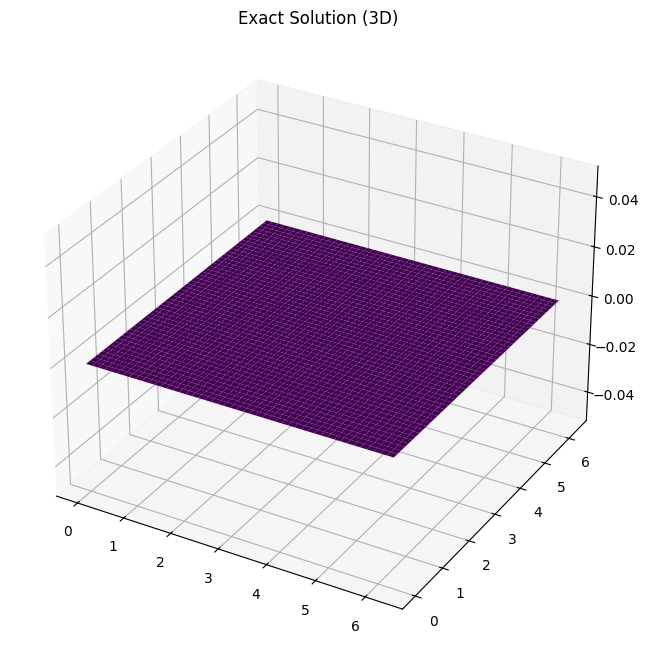

In [35]:
N = 50
a = 0
b = 2 * np.pi

amplitudes = [.2, 0.1, 0.04, 0.05, 0.15]

kx = [3, 1.0, 0, 0.2, 0.4]
ky = [0, 2.0, -1.0, 0.7, -0.1]

kt = [0.2, -1, 0.4, -0.6, 0.8]

phases = [0.0, 0.8, 1.5, 2.2, 0.4]
wave_types = ["cos", "sin", "cos", "sin", "cos"]

u_prms = (amplitudes, kx, ky, kt, phases, wave_types)
t = 0
u_wrapped = lambda coords: u([coords[0], coords[1]], t, *u_prms)
u_exact = get_exact(N, a, b, u_wrapped)

#Plot the exact solution
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.imshow(u_exact.reshape((N-1, N-1)), extent=(a, b, a, b), origin='lower')
plt.colorbar()
plt.title("Exact Solution")
plt.show()

#Make it a 3D surface plot
from mpl_toolkits.mplot3d import Axes3D
X, Y = np.meshgrid(np.linspace(a, b, N-1), np.linspace(a, b, N-1))
Z = u_exact.reshape((N-1, N-1))

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='viridis')
ax.set_title("Exact Solution (3D)")
plt.show()

In [36]:
t_vals = np.linspace(0, 10*np.pi, 100, endpoint=False)

u_intbdy_wrapped = lambda coords: u_bdy(coords[0], coords[1], t)

def delta_a(x, y, a):
    exp_term = np.exp(-(x**2 + y**2)/(2 * a**2))
    return exp_term / (2 * np.pi * a**2)

def get_S_ib(x_vals, a, x_ib_vals):
    N = x_vals.shape[1]-1
    N_ib = x_ib_vals.shape[1]
    S_ib = np.zeros(((N-1)**2, N_ib))
    print(f"I have {S_ib.shape[0]} rows to create.")
    for i in range(1, N):
        for j in range(1, N):
            for k in range(N_ib):
                x = [x_vals[0, i], x_vals[1, j]]
                x_ib = x_ib_vals[:, k]
                S_ib[get_interior_index(i, j, N), k] = delta_a(x[0]-x_ib[0], x[1]-x_ib[1], a)
            print(f"Processed interior index {get_interior_index(i, j, N)} of {(N-1)**2} for all k.")
    print(f"Finished creating S_ib with shape {S_ib.shape}")
    return S_ib

def get_immersed_boundary_u(u, N_bd, x_ib_vals):
    u_ib = np.zeros(N_bd)
    for k in range(N_bd):
        u_ib[k] = u([x_ib_vals[0, k], x_ib_vals[1, k]])
    return u_ib

def get_J_ib_fast(u_approx, S_ib, h):
    return h**2 * (S_ib.T @ u_approx)\

#Let z be the concatenated u and q vectors.
def LHS(z_approx, N, h, A, S_ib):
    print(f"LHS called with z_approx of length {len(z_approx)}")
    assert len(z_approx) == (N-1)**2 + S_ib.shape[1], "Length of z_approx does not match expected size."
    u_approx = z_approx[:(N-1)**2]
    q_approx = z_approx[(N-1)**2:]

    f = A @ u_approx - S_ib @ q_approx
    u_ib = get_J_ib_fast(u_approx, S_ib, h)

    return np.concatenate([f, u_ib])

def RHS(N, a, b, u, u_intbdy, f, x_ib_vals):
    #This is the original rhs, or f modified fot Dirichilet boundary conditions.
    h = (b-a) / N
    x = make_grid(a, b, N)
    B_bd = make_B_bd(N, h)
    u_bd = make_u_bd(N, u, x)
    f_vec = make_f_vec(N, f, x)
    b = make_rhs(f_vec, B_bd, u_bd)

    #Next we make the interior boundary rhs constraint.
    u_ib = get_immersed_boundary_u(u_intbdy, x_ib_vals.shape[1], x_ib_vals)

    return np.concatenate([b, u_ib])

from scipy.sparse.linalg import gmres, LinearOperator

def test_ib(u, u_intbdy, N, a, b, f, x_ib_vals, reg_var):
    print("Starting test_ib")
    x_vals = make_grid(a, b, N)
    h = (b-a) / N
    A = make_A(N, h)
    S_ib = get_S_ib(x_vals, reg_var*h, x_ib_vals)
    right_hand_side = RHS(N, a, b, u, u_intbdy, f, x_ib_vals)
    print("Right hand side shape:", right_hand_side.shape)

    print("Flag 1")

    N_ib = x_ib_vals.shape[1]

    print("Flag 2")

    A_op = LinearOperator(
    shape=((N-1)**2 + N_ib, (N-1)**2 + N_ib),
    matvec=lambda z: LHS(z, N, h, A, S_ib),
    dtype=float
    )

    print("Flag 3")

    solution, info = gmres(
        A_op,
        right_hand_side,
        restart=1000,
        rtol=1e-8,
        atol=0,
        maxiter=1000
    )

    print("Flag 4")

    return solution, info

x_vals = make_grid(a, b, N)
h = (b-a) / N
A = make_A(N, h)

print(x_ib)
x_ib_vals = np.array([x_ib[0], x_ib[1]])
print(x_ib_vals.shape)
print(x_vals.shape)

t = 0

def wrap_u(u, t, u_prms):
    return lambda coords: u([coords[0], coords[1]], t, *u_prms)

def wrap_u_bdy(u_bdy, t):
    return lambda coords: u_bdy([coords[0], coords[1]], t)

def wrap_f(f, t, u_prms):
    return lambda coords: f([coords[0], coords[1]], t, *u_prms)

solution, info = test_ib(wrap_u(u, t, u_prms), wrap_u_bdy(u_bdy, t), N, a, b, wrap_f(f, t, u_prms), x_ib_vals, 1.2)



# # right_hand_side = RHS(N, a, b, u, u_intbdy_wrapped, f, x_ib_all)


C:\Users\cjgir\AppData\Local\Temp\ipykernel_23936\2432620283.py:6: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  return np.row_stack((lnspc, lnspc))


[array([1.91515016, 2.03097963, 2.1221704 , 2.23323859, 2.31429767,
       2.42879934, 2.55011131, 2.69079087, 2.82978061, 2.96133979,
       3.05515522, 3.05074284, 3.12159912, 3.23381951, 3.32807386,
       3.43122906, 3.55935289, 3.62170781, 3.62899883, 3.6800416 ,
       3.80055103, 3.88618936, 3.92211429, 3.98510509, 4.05541307,
       4.05799957, 4.05802756, 4.05754625, 4.12835379, 4.16931708,
       4.22697876, 4.30570521, 4.39822972, 4.39370625, 4.37617996,
       4.33534168, 4.27676503, 4.24613298, 4.22474782, 4.20489708,
       4.24373845, 4.23451807, 4.33677597, 4.35454886, 4.28017981,
       4.11242121, 4.00462221, 3.86071787, 3.78134939, 3.67411766,
       3.78643447, 3.68817267, 3.63372472, 3.64392955, 3.54525707,
       3.41251872, 3.38056474, 3.39868954, 3.43342454, 3.49300969,
       3.57983655, 3.58828834, 3.47362813, 3.36093426, 3.31829046,
       3.2672906 , 3.20294862, 3.15094454, 3.10277637, 3.01180919,
       2.88311168, 2.7704702 , 2.6790203 , 2.75989386, 2.8698

KeyboardInterrupt: 

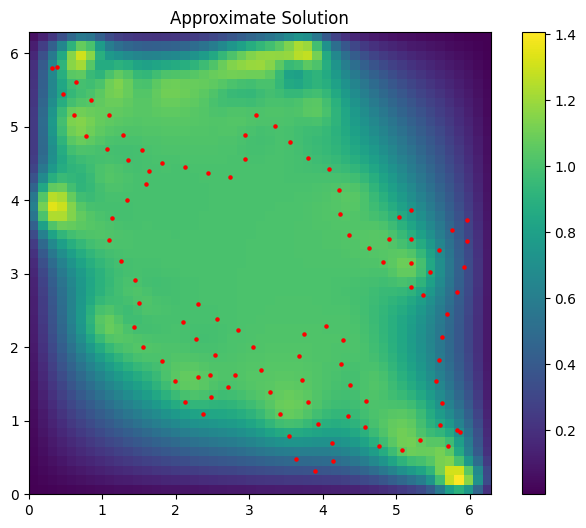

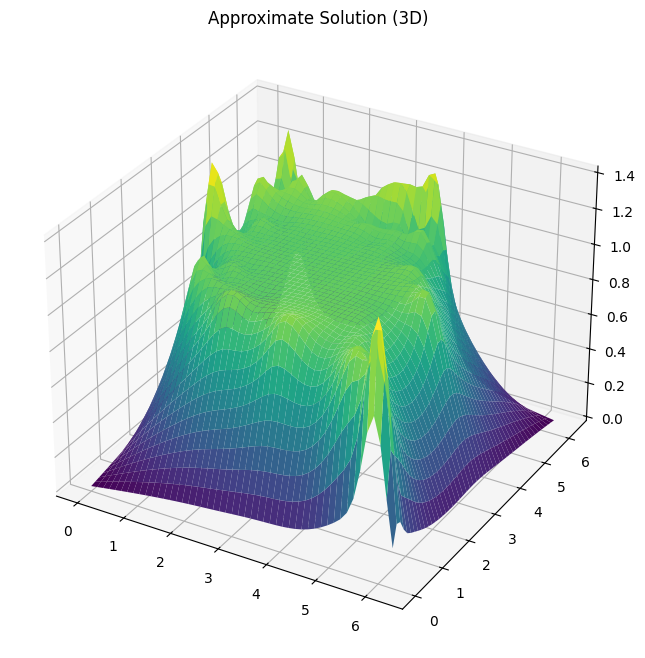

In [ ]:
#Plot the approximate solution
u_approx = solution[: (N-1)**2]
plt.figure(figsize=(8, 6))
plt.imshow(u_approx.reshape((N-1, N-1)), extent=(a, b, a, b), origin='lower')
plt.colorbar()
# Plot immersed-boundary points
plt.scatter(
    x_ib_vals[0, :],
    x_ib_vals[1, :],
    s=5,
    c='red',
    label='Immersed Boundary'
)
plt.title("Approximate Solution")
plt.show()

#Make it a 3D surface plot
X, Y = np.meshgrid(np.linspace(a, b, N-1), np.linspace(a, b, N-1))
Z = u_approx.reshape((N-1, N-1))

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='viridis')
ax.set_title("Approximate Solution (3D)")
plt.show()

In [ ]:
print("Solution info:", info)

Solution info: 0
